# Лабораторна робота №2. Розвідувальний аналіз даних (EDA) для задачі регресії

## Від чого залежить витрата палива автомобіля? Дослідження набору даних Auto MPG

**Курс:** Аналіз та візуалізація даних для науки, освіти та бізнесу
**Виконав:** Табачук Олександр Ігорович, група КН-42
**Мова:** Python (pandas, matplotlib, seaborn, scipy)

---

## Постановка задачі

**Предметна область.** Автомобільна техніка та енергоефективність. Набір даних охоплює легкові автомобілі, що продавалися у США у 1970–1982 роках. Саме в цей період відбулися дві нафтові кризи (1973 і 1979) і з'явилися перші федеральні стандарти економії палива (CAFE, з 1978 р.), тому дані цікаві й з економічного погляду.

**Джерело.** UCI Machine Learning Repository, *Auto MPG* (R. Quinlan, 1993; оригінал — бібліотека StatLib, Carnegie Mellon University).
Сторінка: <https://archive.ics.uci.edu/dataset/9/auto+mpg> · файл: <https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data>
Ліцензія: **CC BY 4.0**. Дані вільно доступні для завантаження й використання з посиланням на джерело.

**Одиниця спостереження:** одна модель (модифікація) автомобіля певного модельного року.

**Цільова змінна:** `mpg` — пробіг у милях на один американський галон палива. Це неперервна кількісна змінна: чим більше значення, тим економніше авто. Для наочності додатково перераховуємо її в звичні для нас **л/100 км** (`l_per_100km = 235.215 / mpg`). Цей стовпець є лише іншим записом цілі, а не фактором.

**Чому це задача регресії.** Ціль кількісна й неперервна. Вона не обчислюється з інших стовпців, а є виміряною характеристикою. Є кілька змістовних потенційних факторів: числові (вага, об'єм двигуна, потужність, розгін, рік) і категоріальні (кількість циліндрів, регіон виробника). Тож дані придатні для описової статистики, а також для дво- та багатовимірного аналізу.

**Мета:** описати розподіл витрати палива, виявити найтісніше пов'язані з нею характеристики та з'ясувати, які фактори можуть спотворювати прості порівняння. Це підготовка до майбутньої регресійної моделі. Модель у цій роботі **не будується**.

### Дослідницькі запитання

1. **RQ1.** Який вигляд має розподіл витрати палива (`mpg`)? Чи є незвичні спостереження?
2. **RQ2.** Які технічні характеристики найсильніше пов'язані з `mpg`? Чи є ці зв'язки лінійними?
3. **RQ3.** Чи відрізняються автомобілі з США, Європи та Японії за економністю, і чи зберігається різниця для авто **однакової ваги**?
4. **RQ4.** Як змінилася економність авто з 1970 по 1982 рік? Це наслідок лише зменшення ваги чи й технічного прогресу?
5. **RQ5.** Наскільки потенційні фактори пов'язані між собою (мультиколінеарність) і що це означає для майбутньої регресії?

### Опис змінних

| Змінна | Тип | Одиниці | Зміст |
|---|---|---|---|
| `mpg` | числова, неперервна | миль/галон (США) | **цільова змінна**, економність палива |
| `cylinders` | дискретна / категоріальна | шт. | кількість циліндрів двигуна (3–8) |
| `displacement` | числова | куб. дюйми | робочий об'єм двигуна |
| `horsepower` | числова | к. с. | потужність двигуна |
| `weight` | числова | фунти | маса автомобіля |
| `acceleration` | числова | с | час розгону 0–60 миль/год (більше = повільніше) |
| `model_year` | дискретна (час) | рік (70 = 1970) | модельний рік |
| `origin` | категоріальна | 1/2/3 | регіон виробника: 1 — США, 2 — Європа, 3 — Японія |
| `car_name` | текстова | — | назва моделі (унікальний ідентифікатор) |

## 0. Встановлення пакетів

Виконати один раз, якщо бібліотеки ще не встановлені (розкоментуйте рядок).

In [1]:
# Автоперевірка залежностей: якщо в обраному ядрі бракує пакетів, вони встановлюються автоматично
import importlib.util, subprocess, sys
REQUIRED = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "scipy": "scipy"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Встановлюю:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
    importlib.invalidate_caches()
print("Python", sys.version.split()[0], "| усі залежності на місці")

Python 3.15.2 | усі залежності на місці


## 0.1. Завантаження бібліотек та налаштування

In [2]:
import json
import platform
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
from IPython.display import display

# Шляхи проєкту (ноутбук запускається з папки notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "auto-mpg.data"
PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "outputs" / "tables"
FIGURES = ROOT / "outputs" / "figures"
META = ROOT / "outputs" / "metadata"
for p in (PROCESSED, TABLES, FIGURES, META):
    p.mkdir(parents=True, exist_ok=True)

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "figure.figsize": (8, 4.5)})
pd.set_option("display.precision", 2)

ORIGIN_COLORS = {"США": "#4C72B0", "Європа": "#55A868", "Японія": "#C44E52"}

def save_fig(fig, name):
    """Зберігає графік у outputs/figures для повторного використання (презентація)."""
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")

## 1. Завантаження даних

Вихідний файл лежить у `data/raw/` без змін. Якщо його немає, він завантажується з відкритого URL UCI.
Формат: значення розділені пробілами, пропуски позначені `?`, назва авто в лапках.

In [3]:
if not RAW.exists():
    RAW.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(DATA_URL, RAW)

COLS = ["mpg", "cylinders", "displacement", "horsepower", "weight",
        "acceleration", "model_year", "origin", "car_name"]
raw = pd.read_csv(RAW, sep=r"\s+", names=COLS, na_values="?", quotechar='"')
raw.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## 2. Первинне ознайомлення

In [4]:
print(f"Спостережень: {raw.shape[0]}, змінних: {raw.shape[1]}")
overview = pd.DataFrame({
    "тип": raw.dtypes.astype(str),
    "унікальних": raw.nunique(),
    "пропусків": raw.isna().sum(),
    "приклад": raw.iloc[0],
})
overview

Спостережень: 398, змінних: 9


,тип,унікальних,пропусків,приклад
mpg,float64,129,0,18.0
cylinders,int64,5,0,8
displacement,float64,82,0,307.0
horsepower,float64,93,6,130.0
weight,float64,351,0,3504.0
acceleration,float64,95,0,12.0
model_year,int64,13,0,70
origin,int64,3,0,1
car_name,str,305,0,chevrolet chevelle malibu


**Висновок.** У даних 398 автомобілів і 9 змінних. Сім змінних числові. `origin` закодована числами 1–3, але за змістом це категорія, тому її треба перекодувати. `cylinders` має лише 5 значень, тож розглядатимемо її і як числову, і як категоріальну. `model_year` — часова компонента (13 років). Усі числові змінні мають американські одиниці (фунти, куб. дюйми), тому для інтерпретації додамо метричні відповідники.

## 3. Оцінка якості даних

### 3.1. Пропуски та дублікати

In [5]:
print("Повних дублікатів рядків:", raw.duplicated().sum())
print("Дублікатів за всіма числовими полями:", raw.duplicated(subset=COLS[:-1]).sum())
print("Повторюваних назв моделей:", raw["car_name"].duplicated().sum())
raw[raw["horsepower"].isna()]

Повних дублікатів рядків: 0
Дублікатів за всіма числовими полями: 0
Повторюваних назв моделей: 93


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i
374,23.0,4,151.0,NaN,3035.0,20.5,82,1,amc concord dl


Дублікатів немає. Повторювані назви моделей (наприклад, *ford pinto*) — це різні модельні роки або модифікації, тобто окремі коректні спостереження.

Пропуски є лише в `horsepower`: **6 із 398 (1,5 %)**. Це звичайні масові моделі (Ford Pinto, Renault 18i тощо), і пропуски розкидані по роках і регіонах. Ознак систематичного механізму пропусків немає.
**Рішення:** не видаляти рядки, бо в них відомі `mpg` та решта факторів. Пропуски заповнюємо **медіаною потужності в групі з тією ж кількістю циліндрів і тим самим регіоном**: потужність сильно залежить від двигуна, тож це точніше за загальну медіану. Заповнені значення позначаємо прапорцем `hp_imputed`, щоб їх можна було виключити в подальшому аналізі.

### 3.2. Коректність значень і текстових полів

In [6]:
# Діапазони числових змінних — перевірка на неможливі значення (нулі, від'ємні)
display(raw.describe().T[["min", "max"]])

# Марка = перше слово назви; шукаємо помилки написання
brand_raw = raw["car_name"].str.split().str[0]
print(sorted(brand_raw.unique()))

,min,max
mpg,9.0,46.6
cylinders,3.0,8.0
displacement,68.0,455.0
horsepower,46.0,230.0
weight,1613.0,5140.0
acceleration,8.0,24.8
model_year,70.0,82.0
origin,1.0,3.0


['amc', 'audi', 'bmw', 'buick', 'cadillac', 'capri', 'chevroelt', 'chevrolet', 'chevy', 'chrysler', 'datsun', 'dodge', 'fiat', 'ford', 'hi', 'honda', 'maxda', 'mazda', 'mercedes', 'mercedes-benz', 'mercury', 'nissan', 'oldsmobile', 'opel', 'peugeot', 'plymouth', 'pontiac', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'triumph', 'vokswagen', 'volkswagen', 'volvo', 'vw']


Числові діапазони правдоподібні: немає нулів чи від'ємних значень, мінімальна вага ≈ 730 кг, максимальна ≈ 2,3 т.

У назвах марок є **помилки та синоніми**: `chevroelt`/`chevy` → chevrolet, `toyouta` → toyota, `maxda` → mazda, `vokswagen`/`vw` → volkswagen, `mercedes-benz` → mercedes, `capri` → mercury, `hi` → international harvester. Виправляємо їх у новому стовпці `brand`.

In [7]:
raw[raw["cylinders"].isin([3, 5])][["car_name", "cylinders", "displacement", "mpg", "model_year"]]

,car_name,cylinders,displacement,mpg,model_year
71,mazda rx2 coupe,3,70.0,19.0,72
111,maxda rx3,3,70.0,18.0,73
243,mazda rx-4,3,80.0,21.5,77
274,audi 5000,5,131.0,20.3,78
297,mercedes benz 300d,5,183.0,25.4,79
327,audi 5000s (diesel),5,121.0,36.4,80
334,mazda rx-7 gs,3,70.0,23.7,80


Змістовна особливість: усі **«3-циліндрові» авто — це Mazda з роторним двигуном Ванкеля** (RX2, RX3, RX-4, RX-7). Ротори в даних закодовано як циліндри, тож фізично це не 3-циліндрові двигуни. «5-циліндрові» — це Audi 5000 і дизельний Mercedes 300D. Ці 7 авто не є помилками, і ми їх не видаляємо. Але групи 3 і 5 циліндрів занадто малі для порівнянь, тому в груповому аналізі за циліндрами їх виділено окремо, а висновки робимо для 4, 6 і 8 циліндрів.

Окремо відзначимо **дизельні моделі** (позначка *diesel* у назві та Mercedes 300D). Їхня економність пояснюється типом пального, а цієї змінної в даних немає. Це обмеження датасету.

### 3.3. Потенційні викиди (правило 1,5·IQR)

In [8]:
NUM = ["mpg", "displacement", "horsepower", "weight", "acceleration"]
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

outl = pd.DataFrame({c: [iqr_outliers(raw[c].dropna()).sum()] for c in NUM}, index=["к-сть викидів (IQR)"])
display(outl)
raw.loc[iqr_outliers(raw["mpg"]), ["car_name", "mpg", "model_year"]]

,mpg,displacement,horsepower,weight,acceleration
к-сть викидів (IQR),1,0,10,0,7


,car_name,mpg,model_year
322,mazda glc,46.6,80


За правилом 1,5·IQR у цілі `mpg` лише **одне** нетипове значення: Mazda GLC 1980 р., 46,6 mpg (≈ 5 л/100 км). Це реальний малолітражний хетчбек, відомий рекордною економністю, а не помилка. «Викиди» за потужністю (10) і розгоном (7) — це реальні потужні V8 або, навпаки, дуже повільні авто.
**Рішення:** викиди **не видаляємо**. Вони описують реальну різноманітність автопарку, а їх видалення штучно звузило б діапазон зв'язків. Для стійкості додатково використовуємо медіани та рангову кореляцію Спірмена.

### 3.4. Очищення та трансформація

In [9]:
BRAND_FIX = {"chevroelt": "chevrolet", "chevy": "chevrolet", "toyouta": "toyota",
             "maxda": "mazda", "vokswagen": "volkswagen", "vw": "volkswagen",
             "mercedes-benz": "mercedes", "capri": "mercury", "hi": "international harvester"}

df = raw.copy()
df["origin"] = df["origin"].map({1: "США", 2: "Європа", 3: "Японія"})
df["origin"] = pd.Categorical(df["origin"], categories=["США", "Європа", "Японія"])
df["brand"] = df["car_name"].str.split().str[0].replace(BRAND_FIX)
df["year"] = 1900 + df["model_year"]
df["diesel"] = df["car_name"].str.contains("diesel") | df["car_name"].str.contains("300d")

# Заповнення пропусків потужності медіаною в групі (циліндри × регіон)
df["hp_imputed"] = df["horsepower"].isna()
df["horsepower"] = df["horsepower"].fillna(
    df.groupby(["cylinders", "origin"], observed=True)["horsepower"].transform("median"))

# Метричні одиниці для інтерпретації
df["l_per_100km"] = 235.215 / df["mpg"]
df["weight_kg"] = df["weight"] * 0.45359
df["displacement_l"] = df["displacement"] * 0.016387

# Вагові групи (терцилі) — для стратифікованих порівнянь
df["weight_group"] = pd.qcut(df["weight_kg"], 3, labels=["легкі", "середні", "важкі"])
w_edges = pd.qcut(df["weight_kg"], 3, retbins=True)[1].round(0)
print("Межі вагових груп, кг:", w_edges)

display(df.loc[df["hp_imputed"], ["car_name", "cylinders", "origin", "horsepower"]])
df.to_csv(PROCESSED / "auto_mpg_clean.csv", index=False, encoding="utf-8")
print("Збережено:", PROCESSED / "auto_mpg_clean.csv", df.shape)

Межі вагових груп, кг: [ 732. 1086. 1496. 2331.]


,car_name,cylinders,origin,horsepower
32,ford pinto,4,США,84.0
126,ford maverick,6,США,100.0
330,renault lecar deluxe,4,Європа,76.0
336,ford mustang cobra,4,США,84.0
354,renault 18i,4,Європа,76.0
374,amc concord dl,4,США,84.0


Збережено: C:\Users\sasha\Desktop\Labs\Lab02_Tabachuk_Oleksandr\data\processed\auto_mpg_clean.csv (398, 17)


## 4. Описова статистика

### 4.1. Числові змінні

In [10]:
num_cols = ["mpg", "l_per_100km", "weight_kg", "displacement_l", "horsepower", "acceleration", "cylinders"]
desc = df[num_cols].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
desc["IQR"] = desc["75%"] - desc["25%"]
desc["range"] = desc["max"] - desc["min"]
desc["CV, %"] = desc["std"] / desc["mean"] * 100
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
desc = desc.round(2)
desc.to_csv(TABLES / "descriptive_statistics.csv", encoding="utf-8")
desc

,count,mean,std,min,5%,25%,50%,75%,95%,max,IQR,range,"CV, %",skew,kurtosis
mpg,398.0,23.51,7.82,9.00,13.00,17.50,23.00,29.00,37.03,46.60,11.50,37.60,33.24,0.46,-0.51
l_per_100km,398.0,11.21,3.90,5.05,6.35,8.11,10.23,13.44,18.09,26.14,5.33,21.09,34.80,0.77,0.12
weight_kg,398.0,1347.35,384.12,731.64,872.48,1008.67,1271.64,1636.55,2024.83,2331.45,627.88,1599.81,28.51,0.53,-0.79
displacement_l,398.0,3.17,1.71,1.11,1.39,1.71,2.43,4.29,6.55,7.46,2.59,6.34,53.91,0.72,-0.75
horsepower,398.0,104.16,38.29,46.00,60.85,76.00,92.00,125.00,180.00,230.00,49.00,184.00,36.76,1.11,0.75
acceleration,398.0,15.57,2.76,8.00,11.28,13.82,15.50,17.18,20.41,24.80,3.35,16.80,17.71,0.28,0.42
cylinders,398.0,5.45,1.70,3.00,4.00,4.00,4.00,8.00,8.00,8.00,4.00,5.00,31.18,0.53,-1.38


**Інтерпретація.**
* **mpg:** середнє 23,5, медіана 23,0, тобто типове авто проїжджає ≈ 23 милі на галон (≈ 10 л/100 км). Середнє трохи більше за медіану, а асиметрія +0,46 помірна правостороння: є «хвіст» дуже економних авто. Мінливість велика (CV ≈ 33 %), діапазон від 9 до 46,6 mpg, тобто економність різниться в 5 разів. Половина авто лежить між 17,5 і 29 mpg.
* **л/100 км** — обернена величина, тому асиметрія в неї протилежна: довгий хвіст «ненажерливих» V8 (до 26 л/100 км).
* **Вага** (медіана ≈ 1,27 т) і **об'єм двигуна** (медіана ≈ 2,4 л) також правоасиметричні: багато компактних авто й менше великих седанів. Потужність має найбільшу асиметрію (≈ 1,1).
* **Розгін** — єдина приблизно симетрична змінна (медіана 15,5 с, асиметрія ≈ 0,3).

### 4.2. Категоріальні змінні: частоти та частки

In [11]:
freq = []
for col in ["origin", "cylinders", "year"]:
    vc = df[col].value_counts().sort_index()
    freq.append(pd.DataFrame({"змінна": col, "значення": vc.index.astype(str),
                              "кількість": vc.values, "частка, %": (vc / len(df) * 100).round(1).values}))
freq = pd.concat(freq, ignore_index=True)
freq.to_csv(TABLES / "category_frequencies.csv", index=False, encoding="utf-8")
display(freq[freq["змінна"] != "year"])
print("Авто за роками: від", df["year"].value_counts().min(), "до", df["year"].value_counts().max())

,змінна,значення,кількість,"частка, %"
0,origin,США,249,62.6
1,origin,Європа,70,17.6
2,origin,Японія,79,19.8
3,cylinders,3,4,1.0
4,cylinders,4,204,51.3
5,cylinders,5,3,0.8
6,cylinders,6,84,21.1
7,cylinders,8,103,25.9


Авто за роками: від 27 до 40


**Інтерпретація.** Вибірка незбалансована за регіоном: **63 % авто з США**, по 18–20 % з Японії та Європи. Тому прості середні по всій вибірці відображають насамперед американський автопарк. За циліндрами переважають 4-циліндрові (51 %), далі 8 (26 %) і 6 (21 %). Роки представлені рівномірно (28–40 авто на рік), тож аналізувати тренд у часі коректно.

## 5. Одновимірний аналіз

### 5.1. Розподіл цільової змінної

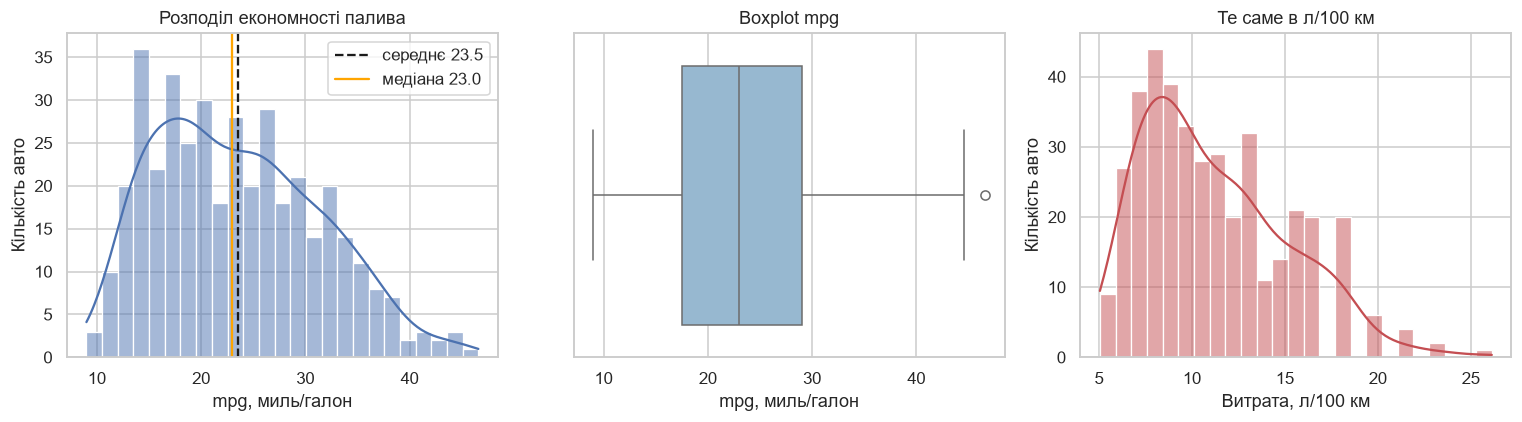

Тест Шапіро–Вілка для mpg: p = 1.18e-07
Тест Шапіро–Вілка для log(mpg): p = 0.000


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(df["mpg"], bins=25, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(df["mpg"].mean(), color="k", ls="--", label=f"середнє {df['mpg'].mean():.1f}")
axes[0].axvline(df["mpg"].median(), color="orange", ls="-", label=f"медіана {df['mpg'].median():.1f}")
axes[0].set(title="Розподіл економності палива", xlabel="mpg, миль/галон", ylabel="Кількість авто")
axes[0].legend()
sns.boxplot(x=df["mpg"], ax=axes[1], color="#8EBAD9")
axes[1].set(title="Boxplot mpg", xlabel="mpg, миль/галон")
sns.histplot(df["l_per_100km"], bins=25, kde=True, ax=axes[2], color="#C44E52")
axes[2].set(title="Те саме в л/100 км", xlabel="Витрата, л/100 км", ylabel="Кількість авто")
fig.tight_layout(); save_fig(fig, "01_target_distribution"); plt.show()

print(f"Тест Шапіро–Вілка для mpg: p = {stats.shapiro(df['mpg']).pvalue:.2e}")
print(f"Тест Шапіро–Вілка для log(mpg): p = {stats.shapiro(np.log(df['mpg'])).pvalue:.3f}")

**Відповідь на RQ1.** Розподіл `mpg` унімодальний, з піком близько 14–20 mpg (великі американські седани) і пологим правим хвостом до 40+ mpg (японські та європейські малолітражки). Нормальним він не є (тест Шапіро–Вілка, p ≪ 0,05). Логарифмування зменшує асиметрію (хоча формально нормальність відкидається й тоді, p ≈ 10⁻⁴), і це варто врахувати при побудові регресії (log або обернена ціль). Справді незвичне лише одне спостереження — Mazda GLC (46,6 mpg), і воно реальне.

### 5.2. Розподіли потенційних факторів

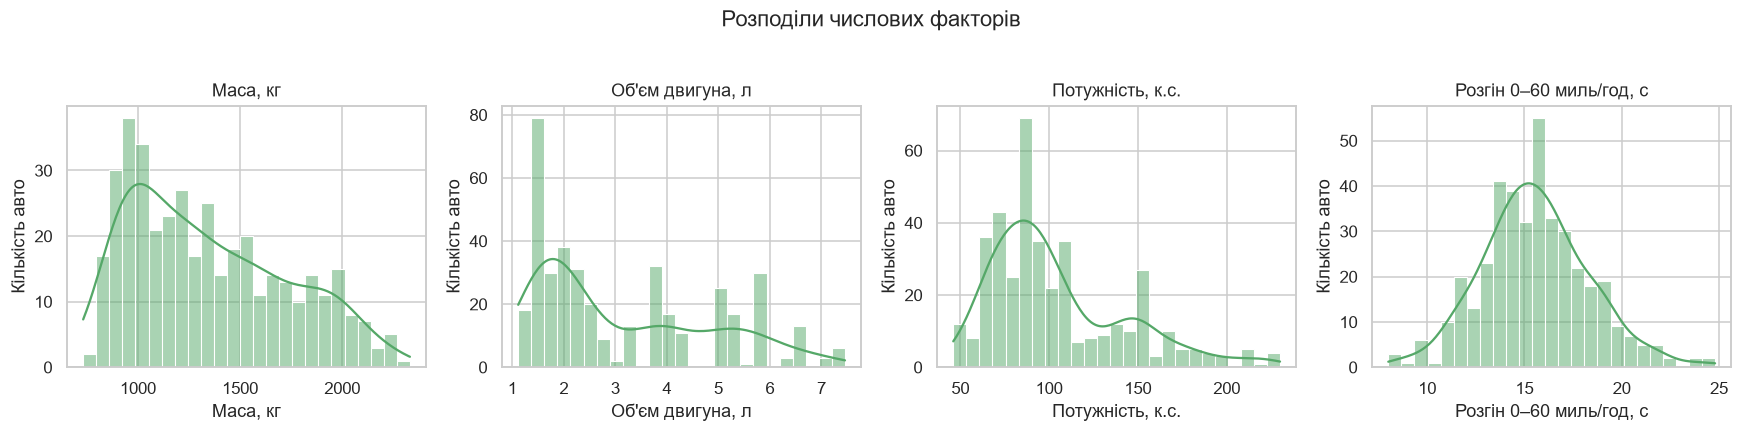

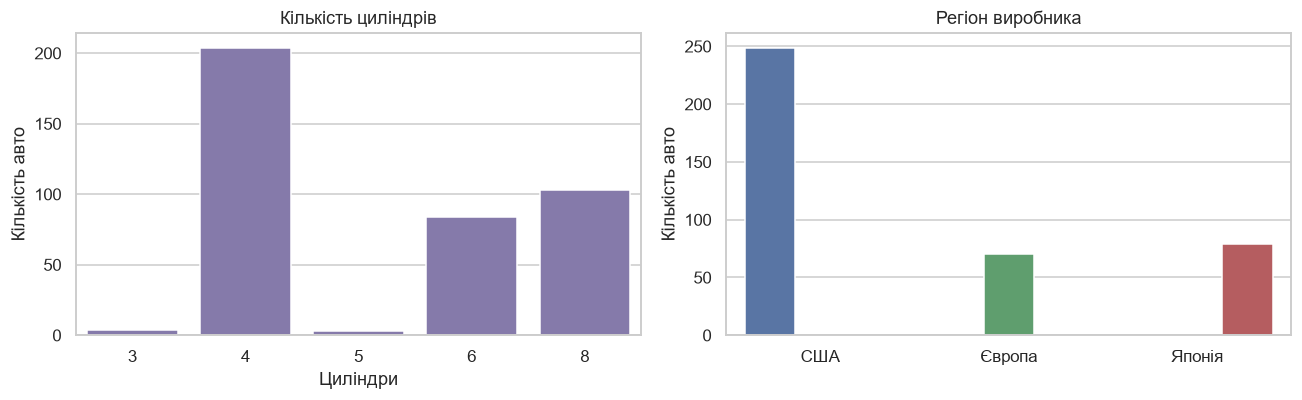

In [13]:
factors = {"weight_kg": "Маса, кг", "displacement_l": "Об'єм двигуна, л",
           "horsepower": "Потужність, к.с.", "acceleration": "Розгін 0–60 миль/год, с"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (c, label) in zip(axes, factors.items()):
    sns.histplot(df[c], bins=25, kde=True, ax=ax, color="#55A868")
    ax.set(title=label, xlabel=label, ylabel="Кількість авто")
fig.suptitle("Розподіли числових факторів", y=1.03)
fig.tight_layout(); save_fig(fig, "02_factor_distributions"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.countplot(x="cylinders", data=df, ax=axes[0], color="#8172B2")
axes[0].set(title="Кількість циліндрів", xlabel="Циліндри", ylabel="Кількість авто")
sns.countplot(x="origin", data=df, ax=axes[1], hue="origin", palette=ORIGIN_COLORS, legend=False)
axes[1].set(title="Регіон виробника", xlabel="", ylabel="Кількість авто")
fig.tight_layout(); save_fig(fig, "03_categorical_counts"); plt.show()

**Інтерпретація.** Об'єм двигуна та потужність мають **двогорбий** розподіл: окремий кластер компактних 4-циліндрових двигунів (1,5–2,5 л, 70–100 к.с.) і кластер великих V8 (5–6 л, 140+ к.с.). Тобто у вибірці фактично два «типи» автомобілів, і це варто враховувати при моделюванні. Маса розподілена ширше й рівніше. Розгін близький до нормального. Серед категорій бачимо, що 8-циліндрові двигуни практично є лише в американських авто (див. розділ 7).

## 6. Двовимірний аналіз

### 6.1. Ціль vs числові фактори

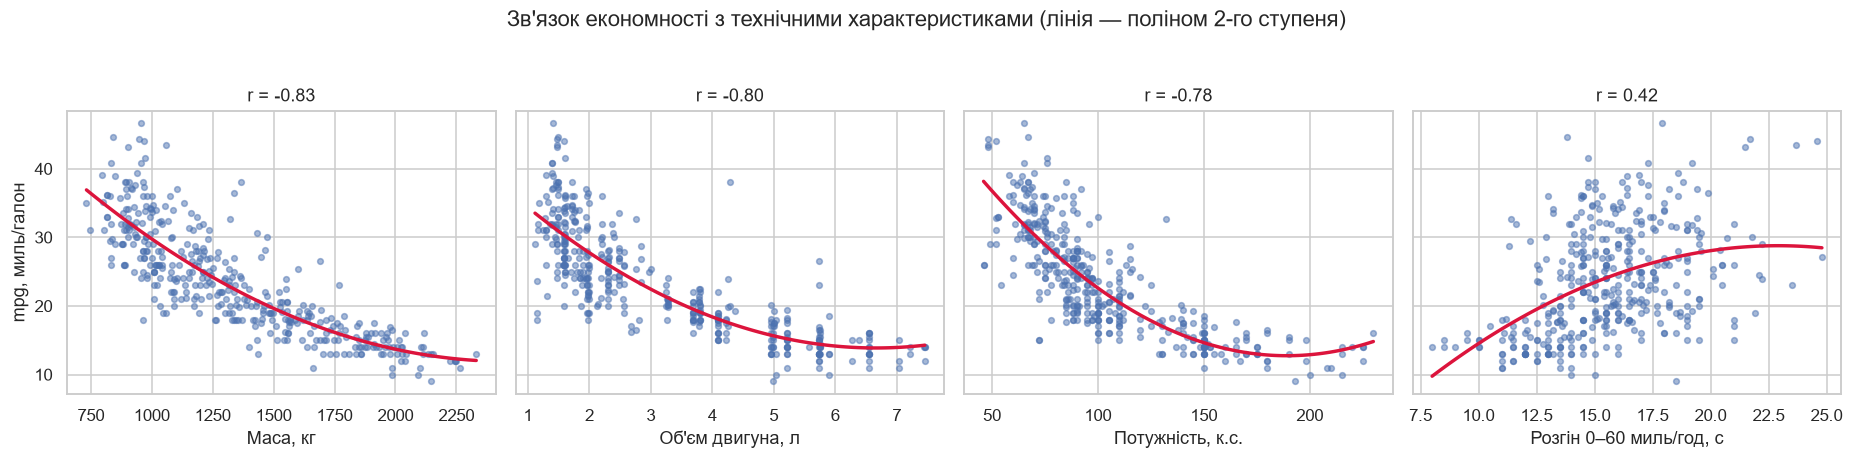

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, (c, label) in zip(axes, factors.items()):
    sns.regplot(x=c, y="mpg", data=df, ax=ax, order=2, ci=None,
                scatter_kws={"s": 14, "alpha": 0.5}, line_kws={"color": "crimson"})
    ax.set(xlabel=label, ylabel="mpg, миль/галон" if ax is axes[0] else "",
           title=f"r = {df[c].corr(df['mpg']):.2f}")
fig.suptitle("Зв'язок економності з технічними характеристиками (лінія — поліном 2-го ступеня)", y=1.04)
fig.tight_layout(); save_fig(fig, "04_mpg_vs_numeric"); plt.show()

In [15]:
rows = []
for c in ["weight_kg", "displacement_l", "horsepower", "cylinders", "acceleration", "year"]:
    rows.append({"фактор": c,
                 "Pearson r (mpg)": df[c].corr(df["mpg"]),
                 "Spearman ρ (mpg)": df[c].corr(df["mpg"], method="spearman"),
                 "Pearson r (л/100км)": df[c].corr(df["l_per_100km"])})
target_corr = pd.DataFrame(rows).set_index("фактор").round(3).sort_values("Spearman ρ (mpg)")
target_corr.to_csv(TABLES / "target_correlations.csv", encoding="utf-8")
target_corr

,Pearson r (mpg),Spearman ρ (mpg),Pearson r (л/100км)
фактор,,,
weight_kg,-0.83,-0.88,0.89
displacement_l,-0.80,-0.86,0.87
horsepower,-0.78,-0.85,0.85
cylinders,-0.78,-0.82,0.84
acceleration,0.42,0.44,-0.46
year,0.58,0.57,-0.56


**Інтерпретація (RQ2).**
* **Напрям і сила.** Найсильніші зв'язки з `mpg` **від'ємні**: маса (r ≈ −0,83), об'єм двигуна (−0,80), потужність (−0,77) і циліндри (−0,78). Чим більше й потужніше авто, тим менше миль воно проїжджає на галоні. Розгін (r ≈ +0,42) і модельний рік (+0,58) пов'язані додатно, тобто повільніші й новіші авто економніші.
* **Форма.** Зв'язки **нелінійні й опуклі**: зі зростанням маси/потужності `mpg` спадає спочатку швидко, а потім повільніше. Тому квадратична крива лягає на точки краще за пряму, а ранговий коефіцієнт Спірмена (|ρ| ≈ 0,85–0,87) вищий за Пірсона.
* **Важливе спостереження:** якщо взяти витрату в **л/100 км** (обернена ціль), зв'язок із масою та об'ємом стає майже **лінійним** (r ≈ 0,89 для маси). Це фізично логічно: на переміщення важчого авто потрібно пропорційно більше пального. Для майбутньої регресії обернена або логарифмована ціль краща за сирий `mpg`.
* Розгін — слабкий фактор із великим розкидом. Його зв'язок з `mpg`, імовірно, опосередкований потужністю: потужні авто розганяються швидше й споживають більше.

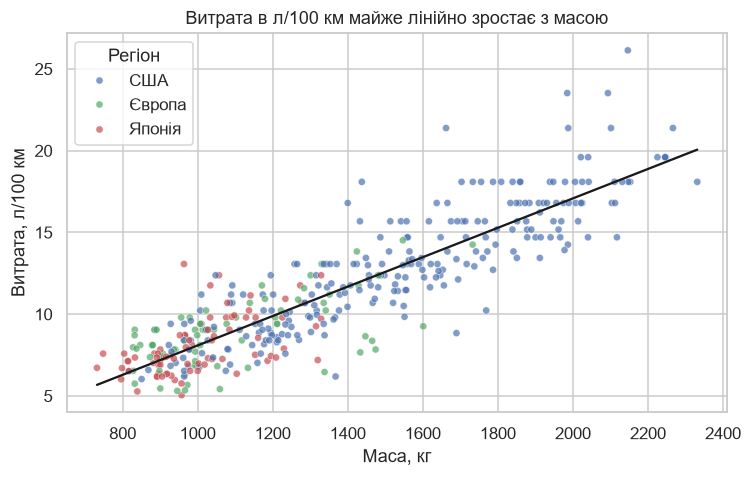

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(x="weight_kg", y="l_per_100km", data=df, hue="origin", palette=ORIGIN_COLORS, s=22, alpha=0.7, ax=ax)
sns.regplot(x="weight_kg", y="l_per_100km", data=df, scatter=False, ci=None, ax=ax, color="k", line_kws={"lw": 1.5})
ax.set(title="Витрата в л/100 км майже лінійно зростає з масою",
       xlabel="Маса, кг", ylabel="Витрата, л/100 км")
ax.legend(title="Регіон")
fig.tight_layout(); save_fig(fig, "05_l100_vs_weight"); plt.show()

### 6.2. Ціль vs категоріальні фактори

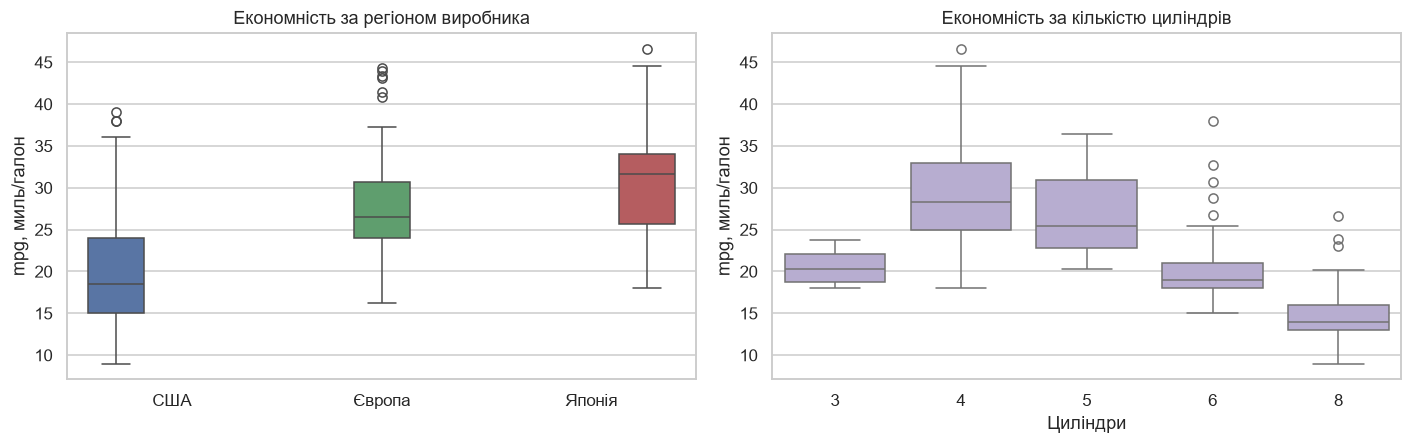

,n,mean,median,std,q25,q75,л/100км (медіана)
origin,,,,,,,
США,249,20.08,18.5,6.40,15.0,24.00,12.71
Європа,70,27.89,26.5,6.72,24.0,30.65,8.88
Японія,79,30.45,31.6,6.09,25.7,34.05,7.44


,n,mean,median,std,q25,q75,л/100км (медіана)
cylinders,,,,,,,
3,4,20.55,20.25,2.56,18.75,22.05,11.62
4,204,29.29,28.25,5.71,25.00,33.00,8.33
5,3,27.37,25.40,8.23,22.85,30.90,9.26
6,84,19.99,19.00,3.81,18.00,21.00,12.38
8,103,14.96,14.00,2.84,13.00,16.00,16.80


Крускал–Уолліс (mpg ~ origin): H = 134.5, p = 6.4e-30


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(x="origin", y="mpg", data=df, hue="origin", palette=ORIGIN_COLORS, legend=False, ax=axes[0])
axes[0].set(title="Економність за регіоном виробника", xlabel="", ylabel="mpg, миль/галон")
sns.boxplot(x="cylinders", y="mpg", data=df, color="#B4A7D6", ax=axes[1])
axes[1].set(title="Економність за кількістю циліндрів", xlabel="Циліндри", ylabel="mpg, миль/галон")
fig.tight_layout(); save_fig(fig, "06_mpg_by_category"); plt.show()

def group_table(col):
    g = df.groupby(col, observed=True)["mpg"].agg(n="count", mean="mean", median="median", std="std",
                                                  q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
    g["л/100км (медіана)"] = 235.215 / g["median"]
    return g.round(2)

by_origin = group_table("origin"); by_cyl = group_table("cylinders")
display(by_origin, by_cyl)
kw = stats.kruskal(*[g["mpg"] for _, g in df.groupby("origin", observed=True)])
print(f"Крускал–Уолліс (mpg ~ origin): H = {kw.statistic:.1f}, p = {kw.pvalue:.1e}")

**Інтерпретація.**
* **Регіон.** Медіанне японське авто проїжджає 31,6 mpg (≈ 7,4 л/100 км), європейське — 26,5 (≈ 8,9 л/100 км), американське — лише 18,5 (≈ 12,7 л/100 км). Відмінності статистично значущі (тест Крускала–Уолліса, p ≈ 10⁻³⁰). Американська група має довгий діапазон: від 9 до 39 mpg.
* **Циліндри.** Залежність ступінчаста й немонотонна на краях: 4-циліндрові — найекономніші (медіана ≈ 28 mpg), далі 6 (≈ 19) і 8 (≈ 14). Групи 3 і 5 циліндрів (роторні Mazda та кілька Audi/Mercedes) містять лише 4 і 3 авто, тож висновків про них не робимо.
* **Але** ці прості порівняння можуть вводити в оману: регіони сильно відрізняються за розміром авто. Перевіряємо це в розділі 7.

### 6.3. Часова компонента: економність за модельними роками

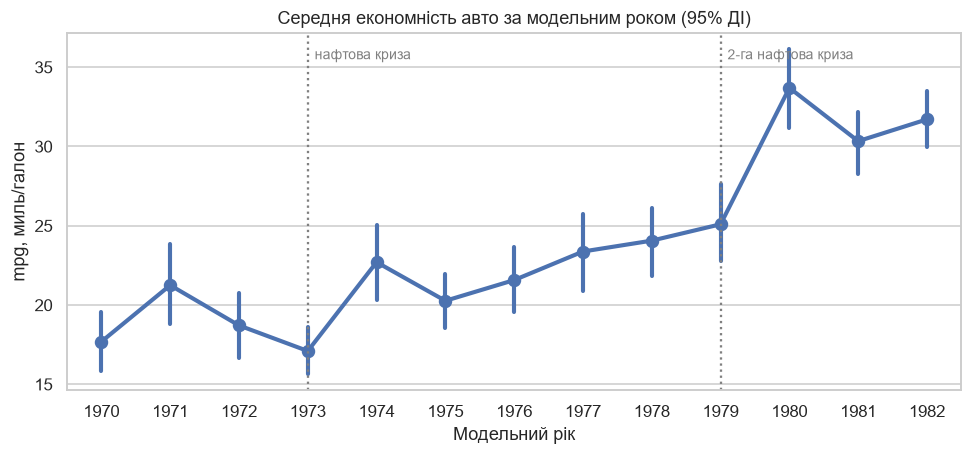

,mpg_mean,mpg_median,weight_kg,horsepower,share_4cyl,n
year,,,,,,
1970,17.7,16.0,1529.9,147.8,24.1,29
1971,21.2,19.0,1358.7,106.2,46.4,28
1972,18.7,18.5,1468.6,120.2,50.0,28
1973,17.1,16.0,1550.8,130.5,27.5,40
1974,22.7,24.0,1305.4,94.4,55.6,27
1975,20.3,19.5,1441.0,101.1,40.0,30
1976,21.6,21.0,1396.5,101.1,44.1,34
1977,23.4,21.8,1359.6,105.1,50.0,28
1978,24.1,20.7,1298.1,99.7,47.2,36


In [18]:
yearly = df.groupby("year").agg(mpg_mean=("mpg", "mean"), mpg_median=("mpg", "median"),
                                weight_kg=("weight_kg", "mean"), horsepower=("horsepower", "mean"),
                                share_4cyl=("cylinders", lambda s: (s == 4).mean() * 100), n=("mpg", "size")).round(1)
yearly.to_csv(TABLES / "yearly_trend.csv", encoding="utf-8")

fig, ax = plt.subplots(figsize=(9, 4.3))
sns.pointplot(x="year", y="mpg", data=df, errorbar=("ci", 95), ax=ax, color="#4C72B0")
for y, lbl in [(1973, "нафтова криза"), (1979, "2-га нафтова криза")]:
    ax.axvline(y - 1970, color="grey", ls=":"); ax.text(y - 1970 + 0.1, 35.5, lbl, fontsize=9, color="grey")
ax.set(title="Середня економність авто за модельним роком (95% ДІ)", xlabel="Модельний рік", ylabel="mpg, миль/галон")
fig.tight_layout(); save_fig(fig, "07_mpg_by_year"); plt.show()
yearly

**Інтерпретація.** Середня економність зросла з ≈ 17,7 mpg (1970) до ≈ 31,7 mpg (1982), **майже вдвічі** (з ≈ 13 до ≈ 7,4 л/100 км). Зростання нерівномірне: до 1973 р. змін немає, після першої нафтової кризи починається поступове покращення, а 1980 р. дає різкий стрибок (+8,6 mpg). Одночасно падає середня маса (≈ 1,53 т → 1,11 т) і потужність (148 → 82 к.с.), а частка 4-циліндрових двигунів росте. Отже, частина тренду — це зміна **структури** автопарку. Чи є покращення в межах однакових авто, перевіримо далі.

## 7. Багатовимірний аналіз

### 7.1. Кореляційна матриця та мультиколінеарність

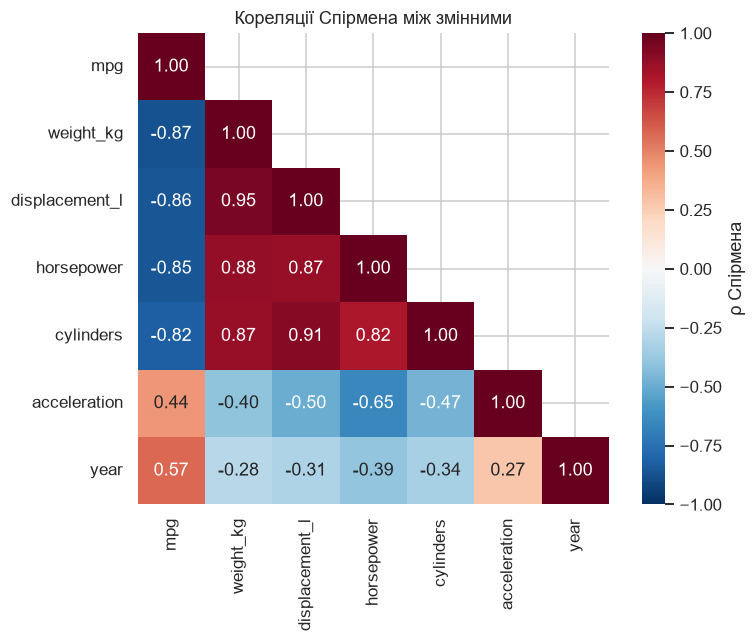

displacement_l    19.8
weight_kg         10.6
cylinders         10.6
horsepower         9.3
acceleration       2.6
year               1.2
Name: VIF, dtype: float64

In [19]:
corr_cols = ["mpg", "weight_kg", "displacement_l", "horsepower", "cylinders", "acceleration", "year"]
corr = df[corr_cols].corr(method="spearman")
corr.round(3).to_csv(TABLES / "correlations.csv", encoding="utf-8")
df[corr_cols].corr().round(3).to_csv(TABLES / "correlations_pearson.csv", encoding="utf-8")

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cbar_kws={"label": "ρ Спірмена"}, ax=ax)
ax.set_title("Кореляції Спірмена між змінними")
fig.tight_layout(); save_fig(fig, "08_correlation_heatmap"); plt.show()

# VIF = діагональ оберненої кореляційної матриці факторів (без цілі)
X = df[corr_cols[1:]]
vif = pd.Series(np.diag(np.linalg.inv(X.corr().values)), index=X.columns, name="VIF").round(1)
vif.to_csv(TABLES / "vif.csv", encoding="utf-8")
vif.sort_values(ascending=False)

**Інтерпретація (RQ5).** Маса, об'єм двигуна, потужність і кількість циліндрів утворюють **блок дуже сильно пов'язаних змінних** (ρ = 0,85–0,95). Фактично вони вимірюють одне явище — «розмір і потужність авто». Коефіцієнти інфляції дисперсії (VIF) для об'єму двигуна (≈ 20), маси та циліндрів (≈ 10,6) перевищують 10, а для потужності ≈ 9. Це класична ознака мультиколінеарності. Для майбутньої регресії це означає таке: включати всі чотири змінні одночасно ризиковано, бо коефіцієнти будуть нестабільними й важко інтерпретованими. Розумніше обрати 1–2 представники (наприклад, масу й потужність) або об'єднати їх. Модельний рік слабко пов'язаний із цим блоком (|ρ| ≈ 0,3–0,4), тож він несе **окрему** інформацію.

### 7.2. Регіон чи вага? Перевірка змішувального фактора (RQ3)

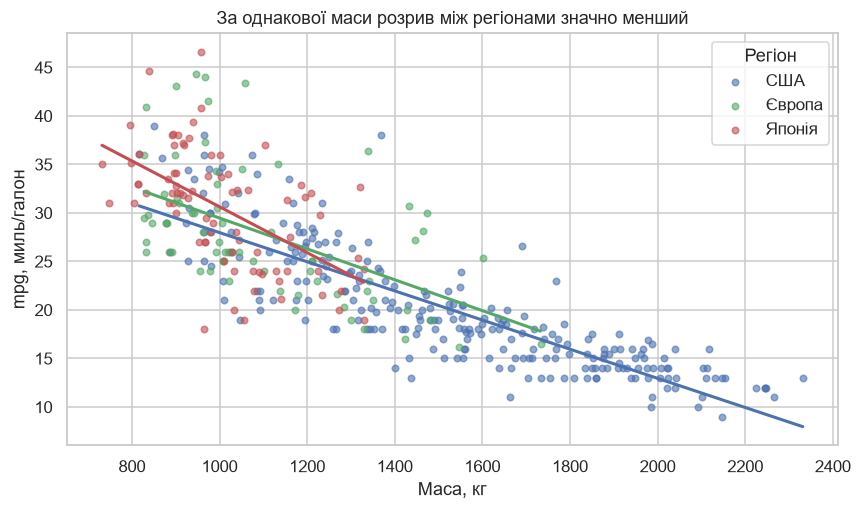

Середня маса за регіоном, кг: {'США': 1525.0, 'Європа': 1099.0, 'Японія': 1008.0}


origin,США,Європа,Японія,Разом
weight_group,,,,
легкі,34,42,58,134
середні,85,25,21,131
важкі,130,3,0,133
Разом,249,70,79,398


origin,США,Європа,Японія
weight_group,,,
легкі,30.0,30.8,32.0
середні,22.8,24.0,26.2
важкі,15.7,19.4,NaN
Уся вибірка,20.1,27.9,30.5


In [20]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for o, g in df.groupby("origin", observed=True):
    ax.scatter(g["weight_kg"], g["mpg"], s=18, alpha=0.6, label=o, color=ORIGIN_COLORS[o])
    z = np.polyfit(g["weight_kg"], g["mpg"], 1)
    xs = np.linspace(g["weight_kg"].min(), g["weight_kg"].max(), 50)
    ax.plot(xs, np.polyval(z, xs), color=ORIGIN_COLORS[o], lw=2)
ax.set(title="За однакової маси розрив між регіонами значно менший",
       xlabel="Маса, кг", ylabel="mpg, миль/галон")
ax.legend(title="Регіон")
fig.tight_layout(); save_fig(fig, "09_mpg_weight_by_origin"); plt.show()

print("Середня маса за регіоном, кг:", df.groupby("origin", observed=True)["weight_kg"].mean().round(0).to_dict())
display(pd.crosstab(df["weight_group"], df["origin"], margins=True, margins_name="Разом"))

strat = df.pivot_table(index="weight_group", columns="origin", values="mpg", aggfunc=["mean", "count"], observed=True).round(1)
overall = df.groupby("origin", observed=True)["mpg"].mean().round(1)
group_comparison = df.groupby(["weight_group", "origin"], observed=True)["mpg"].agg(
    n="count", mean="mean", median="median").round(2).reset_index()
group_comparison.to_csv(TABLES / "group_comparison.csv", index=False, encoding="utf-8")
strat_mean = strat["mean"]; strat_mean.loc["Уся вибірка"] = overall
strat_mean

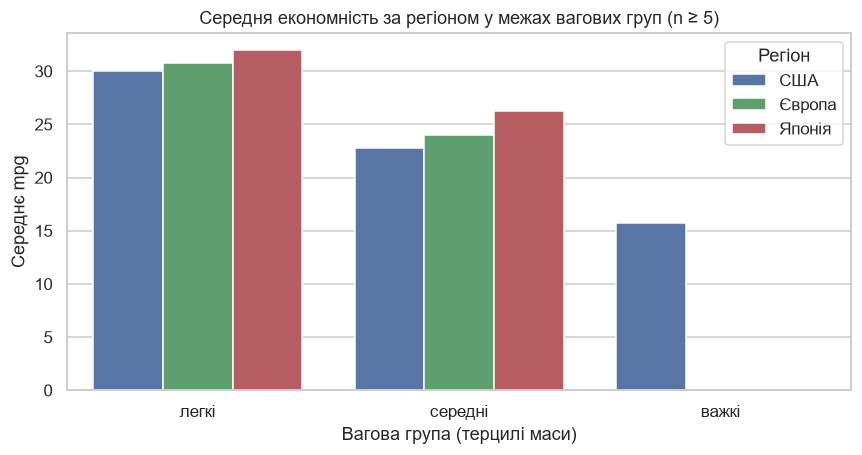

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.3))
plot_df = group_comparison[group_comparison["n"] >= 5]
sns.barplot(x="weight_group", y="mean", hue="origin", data=plot_df, palette=ORIGIN_COLORS, ax=ax)
ax.set(title="Середня економність за регіоном у межах вагових груп (n ≥ 5)",
       xlabel="Вагова група (терцилі маси)", ylabel="Середнє mpg")
ax.legend(title="Регіон")
fig.tight_layout(); save_fig(fig, "10_origin_within_weight"); plt.show()

**Інтерпретація (RQ3).** На всій вибірці японські авто економніші за американські на **≈ 10 mpg** (30,5 проти 20,1). Однак японські та європейські авто в середньому на 430–520 кг легші, а у важкій групі американських авто 130, японських — жодного. **Маса є змішувальним фактором (confounder):** вона пов'язана і з регіоном, і з витратою палива.
Якщо порівнювати авто **однакової вагової групи**, розрив різко зменшується: серед легких — 30,0 (США) проти 32,0 (Японія), лише ≈ 2 mpg; серед середніх — ≈ 3,4 mpg. Тобто більша частина «японської переваги» пояснюється тим, що японці продавали в США менші й легші авто. Невелика залишкова перевага є (можливо, через технології двигунів), але її не можна трактувати як причинний ефект країни. Різницю для важкої групи оцінити неможливо через відсутність японських авто — це обмеження даних.

### 7.3. Технічний прогрес чи полегшення авто? (RQ4)

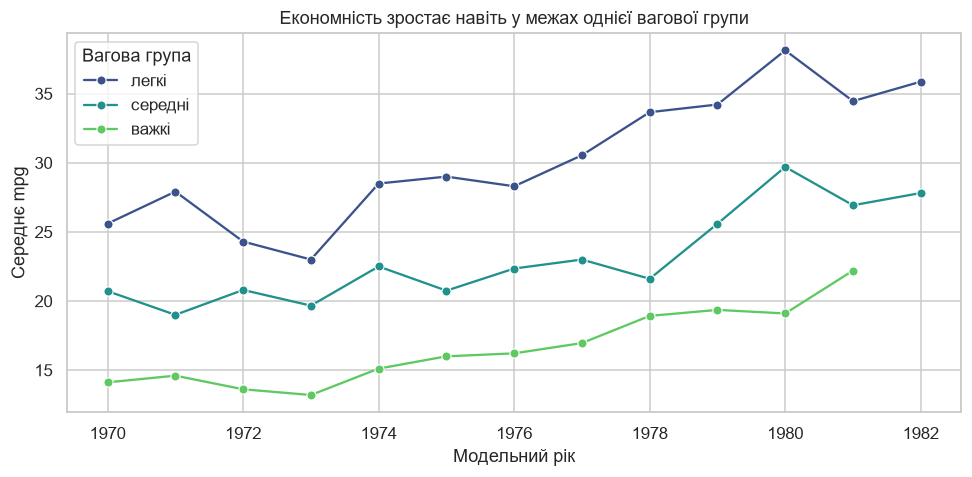

Середній приріст mpg за рік у межах групи: {'легкі': np.float64(1.07), 'середні': np.float64(0.81), 'важкі': np.float64(0.67)}
Загальний приріст mpg за рік: 1.22


weight_group,легкі,середні,важкі
year,,,
1970,25.6,20.7,14.1
1971,27.9,19.0,14.6
1972,24.3,20.8,13.6
1973,23.0,19.7,13.2
1974,28.5,22.5,15.1
1975,29.0,20.8,16.0
1976,28.3,22.4,16.2
1977,30.5,23.0,17.0
1978,33.7,21.6,18.9


In [22]:
trend = df.pivot_table(index="year", columns="weight_group", values="mpg", aggfunc="mean", observed=True).round(1)
trend.to_csv(TABLES / "mpg_by_year_weight_group.csv", encoding="utf-8")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(x="year", y="mpg", hue="weight_group", data=df, estimator="mean", errorbar=None,
             marker="o", palette="viridis", ax=ax)
ax.set(title="Економність зростає навіть у межах однієї вагової групи",
       xlabel="Модельний рік", ylabel="Середнє mpg")
ax.legend(title="Вагова група")
fig.tight_layout(); save_fig(fig, "11_year_trend_by_weight"); plt.show()

slopes = {g: np.polyfit(sub["year"], sub["mpg"], 1)[0] for g, sub in df.groupby("weight_group", observed=True)}
print("Середній приріст mpg за рік у межах групи:", {k: round(v, 2) for k, v in slopes.items()})
print("Загальний приріст mpg за рік:", round(np.polyfit(df["year"], df["mpg"], 1)[0], 2))
trend

**Інтерпретація (RQ4).** У **кожній** ваговій групі економність зростає з роками: легкі авто з ≈ 26 до ≈ 36 mpg, важкі з ≈ 14 до ≈ 22 mpg. Отже, покращення не зводиться лише до того, що авто стали легшими. За однакової маси новіші моделі теж економніші, що свідчить про технічні зміни (двигуни, трансмісії, аеродинаміка). Водночас нахил у межах груп (≈ 0,7–1,1 mpg/рік) менший за загальний (≈ 1,2 mpg/рік). Різниця — це внесок зміни структури автопарку в бік легших авто. Тобто працюють **обидва** механізми. Для регресії це означає, що рік і маса є взаємодоповнювальними факторами, і обидва варто включати.

### 7.4. Спільний огляд ключових змінних

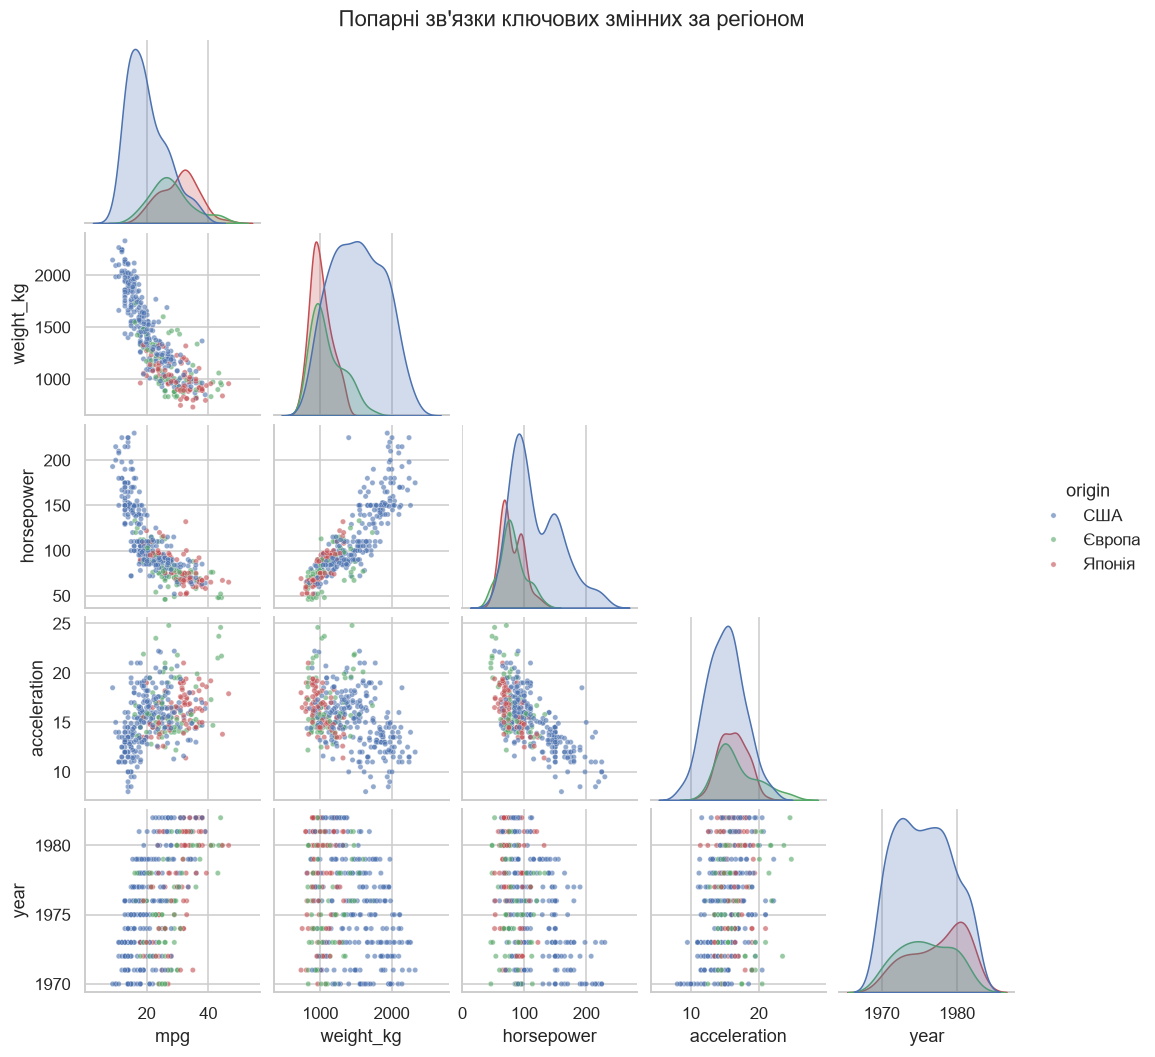

In [23]:
g = sns.pairplot(df[["mpg", "weight_kg", "horsepower", "acceleration", "year", "origin"]],
                 hue="origin", palette=ORIGIN_COLORS, corner=True, plot_kws={"s": 12, "alpha": 0.6},
                 diag_kind="kde", height=1.9)
g.figure.suptitle("Попарні зв'язки ключових змінних за регіоном", y=1.01)
g.savefig(FIGURES / "12_pairplot.png", bbox_inches="tight"); plt.show()

**Інтерпретація.** Матриця розсіювання підтверджує висновки вище. Японські й європейські авто займають ліву (легку, малопотужну) частину простору факторів, а американські покривають увесь діапазон. Потужність і розгін пов'язані обернено (потужніші авто швидше розганяються). Нахил зв'язку `mpg` з масою схожий для всіх регіонів, тож явної **взаємодії** регіон × маса не видно: ефект ваги приблизно однаковий незалежно від країни.

## 8. Висновки

**Відповіді на дослідницькі запитання**

1. **RQ1 — розподіл цілі.** Економність варіюється від 9 до 46,6 mpg (≈ 26 → 5 л/100 км), медіана 23 mpg (≈ 10 л/100 км). Розподіл унімодальний з помірною правосторонньою асиметрією й не є нормальним. Логарифмування або перехід до л/100 км робить його ближчим до симетричного. Єдине нетипове значення (Mazda GLC, 46,6 mpg) реальне й залишене в даних.
2. **RQ2 — найважливіші фактори.** Найсильніше з `mpg` пов'язані маса (ρ ≈ −0,87), об'єм двигуна, потужність і кількість циліндрів (|ρ| ≈ 0,82–0,86). Усі зв'язки від'ємні й **нелінійні** (опуклі). У шкалі л/100 км зв'язок з масою стає майже лінійним (r ≈ 0,89). Модельний рік має помірний додатний зв'язок (ρ ≈ 0,57), розгін — слабкий.
3. **RQ3 — регіон.** Японські (медіана 31,6 mpg) і європейські (26,5) авто значно економніші за американські (18,5). Проте більшість цієї різниці пояснюється **масою**: у межах однакових вагових груп розрив скорочується з ≈ 10 до ≈ 2–3 mpg. Маса — змішувальний фактор, і простий висновок «японські авто економніші, бо вони японські» некоректний.
4. **RQ4 — динаміка 1970–1982.** Середня економність зросла майже вдвічі (≈ 17,7 → 31,7 mpg), найрізкіше після нафтових криз, особливо у 1980 р. Зростання відбувалося і через полегшення автопарку, і через покращення в межах однакової ваги (≈ 0,7–1,1 mpg/рік).
5. **RQ5 — мультиколінеарність.** Маса, об'єм, потужність і циліндри утворюють тісно пов'язаний блок (ρ до 0,95, VIF > 10). У регресії варто брати 1–2 з них, а рік і регіон додавати як окремі незалежні джерела інформації.

**Найважливіші знахідки:** (1) маса авто — головний фактор економності; (2) порівняння за регіоном без урахування маси спотворене; (3) за 12 років відбувся реальний технологічний прогрес, а не лише «зменшення машин».

**Обмеження даних.** Дані старі (1970–1982) й описують лише ринок США, тому висновки не переносяться на сучасні авто (гібриди, турбо, електромобілі). Вибірка невелика (398 авто) й незбалансована (63 % США; японських важких авто немає). Немає важливих змінних: тип палива (дизель лише в назві), тип трансмісії, аеродинаміка, ціна, обсяг продажів (кожна модель має однакову вагу незалежно від популярності). «Циліндри» для роторних двигунів закодовано умовно. Дослідження спостережне, тому виявлені зв'язки **не є доведеним причинним впливом**.

**Подальші кроки.** Побудувати регресію для `log(mpg)` або л/100 км з факторами маса + потужність + рік + регіон. Перевірити взаємодії (рік × маса), нелінійні члени та стійкість до виключення дизелів і роторних двигунів. Порівняти з сучасними даними EPA fueleconomy.gov.

## 9. Збереження метаданих

In [24]:
metadata = {
    "dataset": "Auto MPG",
    "source": "UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/9/auto+mpg",
    "download_url": DATA_URL,
    "license": "CC BY 4.0",
    "n_rows_raw": int(raw.shape[0]), "n_rows_clean": int(df.shape[0]),
    "target": "mpg (miles per US gallon); l_per_100km = 235.215 / mpg",
    "transformations": [
        "origin 1/2/3 -> США/Європа/Японія (categorical)",
        "brand extracted from car_name; typos fixed: " + ", ".join(f"{k}->{v}" for k, v in BRAND_FIX.items()),
        "horsepower: 6 missing values imputed with median by (cylinders, origin); flag hp_imputed",
        "added metric units: weight_kg, displacement_l, l_per_100km; year = 1900 + model_year",
        "weight_group = weight terciles (легкі/середні/важкі)",
        "diesel flag from car name; no outliers removed",
    ],
    "packages": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "matplotlib": matplotlib.__version__, "seaborn": sns.__version__, "scipy": scipy.__version__},
}
(META / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(metadata["packages"], indent=2))

{
  "python": "3.15.2",
  "pandas": "3.1.0",
  "numpy": "2.5.4",
  "matplotlib": "3.11.2",
  "seaborn": "0.13.2",
  "scipy": "1.18.1"
}
